# Machine Learning Assignment 2 — Guided UCI WDBC Classification

**Purpose:** Learn the full mathematical and Python workflow underlying the five-model assignment, check every required metric, and explain why preprocessing must be fitted only to training data.

**Data origin:** UCI Wisconsin Diagnostic Breast Cancer (WDBC), carried in scikit-learn's documented packaged copy. **Not medical advice.**

**Run context:** Open this notebook from within its `notebooks/` directory. Each cell is intended to be executed top to bottom. You must independently execute the project in BITS Virtual Lab for your authentic screenshot and submission.

**Name:** Tushar Pilania\
**BITS ID:** 2026AK05293


## 1. Imports, fixed random seed, and reading the UCI-origin CSV
We reserve `diagnosis` as the label; all other 30 columns are quantitative features. The source data has 569 records, and the original ID was excluded.

In [4]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             matthews_corrcoef, accuracy_score, precision_score, recall_score, f1_score, make_scorer)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from train_models import MODEL_SPECIFICATIONS, create_pipeline
from ml_utils import evaluate_classifier

source = pd.read_csv(PROJECT_ROOT / "data" / "uci_wdbc_dataset.csv")
print("Dataset shape:", source.shape)
print("Diagnosis label counts:\n", source["diagnosis"].value_counts())
print("Missing cells:", int(source.isna().sum().sum()))
source.head()

Dataset shape: (569, 31)
Diagnosis label counts:
 diagnosis
B    357
M    212
Name: count, dtype: int64
Missing cells: 0


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


## 2. Prepare predictors and target

Convert `B` to 0 (benign) and `M` to 1 (malignant). Positive class = **malignant** consistently throughout the notebook. Do not accidentally use the opposite default coding of scikit-learn's original dataset loader.

In [6]:
feature_columns = [column for column in source.columns if column != "diagnosis"]
X = source[feature_columns]
y = source["diagnosis"].map({"B": 0, "M": 1}).astype(int)
print("Predictors:", X.shape[1], "  Malignant class ratio:", round(float(y.mean()), 4))
assert X.shape == (569, 30)
assert y.isin([0, 1]).all()

Predictors: 30   Malignant class ratio: 0.3726


## 3. Stratified train/test split

A fixed seed reproduces the same rows each time. Stratification approximately preserves the benign/malignant ratio in training and held-out test data. Fitting scaling to the entire dataset **before** splitting would leak information and invalidate evaluation.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train), "Test rows:", len(X_test))
print("Train labels:", y_train.value_counts().to_dict())
print("Test labels:", y_test.value_counts().to_dict())

Training rows: 455 Test rows: 114
Train labels: {0: 285, 1: 170}
Test labels: {0: 72, 1: 42}


## 4. Algorithms and their assumptions

1. **Logistic Regression** estimates a linear log-odds decision boundary; scaling is usually beneficial for numerical stability and regularization.
2. **Decision Tree** recursively chooses splits that reduce impurity; easily interpreted but prone to overfitting.
3. **KNN** predicts using nearby training examples; requires scaling because Euclidean distances depend on measurement units.
4. **Gaussian Naive Bayes** assumes feature-wise conditional independence and Gaussian class-conditional densities.
5. **Support Vector Machine (RBF)** learns a nonlinear margin-based boundary; requires scaling for consistent kernel distance interpretation.

**Pipelines:** Median imputation is fitted on training folds only. StandardScaler is used for LR, KNN and SVM. Models receive identical train/test records but appropriate preprocessing.

## 5. Five-fold CV on training rows; fit once; test once

Cross-validation is used as a training-only robustness check. We compute the six metrics on the held-out test partition **after** fitting. Cross-validation clones the pipeline and learns scaling only from each inner training fold.

In [11]:
all_fitted = {}
results = []
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for model_name, (filename, needs_scaling, estimator) in MODEL_SPECIFICATIONS.items():
    pipeline = create_pipeline(needs_scaling, estimator)
    cv_values = cross_val_score(pipeline, X_train, y_train, cv=folds,
                                scoring=make_scorer(matthews_corrcoef), n_jobs=1)
    pipeline.fit(X_train, y_train)
    all_fitted[model_name] = pipeline
    results.append({"ML Model Name": model_name, **evaluate_classifier(pipeline, X_test, y_test),
                    "CV MCC mean": cv_values.mean()})
comparison_table = pd.DataFrame(results).set_index("ML Model Name")
comparison_table.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC,CV MCC mean
ML Model Name,,,,,,,
Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245,0.9444
Decision Tree,0.9035,0.9471,0.9429,0.7857,0.8571,0.7926,0.8408
KNN,0.9561,0.9835,0.9744,0.9048,0.9383,0.9058,0.9394
Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715,0.8737
Support Vector Machine,0.9737,0.9947,0.9756,0.9524,0.9639,0.9433,0.9492


## 6. Confusion matrix orientation and mathematical metric derivation

Our confusion matrix is laid out as **rows = true labels**, **columns = predicted labels**, with class order `[0 (benign), 1 (malignant)]`. Therefore it is `[[TN, FP], [FN, TP]]`.

\[\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\]
\[\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN}\]
\[F_1=\frac{2\,P\,R}{P+R}\]
\[\text{MCC}=\frac{TP\,TN-FP\,FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}\]

AUC is the **area under the ROC curve** made from malignant-class predicted probabilities; it cannot be derived from a single thresholded confusion matrix.

In [13]:
chosen = all_fitted["Support Vector Machine"]
y_predicted = chosen.predict(X_test)
TN, FP, FN, TP = confusion_matrix(y_test, y_predicted, labels=[0, 1]).ravel()
accuracy_manual = (TP + TN) / (TP + TN + FP + FN)
precision_manual = TP / (TP + FP) if TP + FP else 0.0
recall_manual = TP / (TP + FN) if TP + FN else 0.0
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual) if precision_manual + recall_manual else 0.0
mcc_manual = (TP * TN - FP * FN) / np.sqrt((TP+FP)*(TP+FN)*(TN+FP)*(TN+FN))
probability_malignant = chosen.predict_proba(X_test)[:, list(chosen.classes_).index(1)]
auc_calculated = roc_auc_score(y_test, probability_malignant)
print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")
print({"Accuracy": accuracy_manual, "Precision": precision_manual, "Recall": recall_manual,
       "F1": f1_manual, "MCC": mcc_manual, "AUC": auc_calculated})
assert np.isclose(accuracy_manual, accuracy_score(y_test, y_predicted))
assert np.isclose(mcc_manual, matthews_corrcoef(y_test, y_predicted))

TN=71, FP=1, FN=2, TP=40
{'Accuracy': np.float64(0.9736842105263158), 'Precision': np.float64(0.975609756097561), 'Recall': np.float64(0.9523809523809523), 'F1': np.float64(0.963855421686747), 'MCC': np.float64(0.9433397594898876), 'AUC': 0.9947089947089947}


## 7. Confusion matrix and ROC curves

The false negatives (malignant incorrectly predicted benign) are in the lower-left matrix cell. More ROC AUC means better ranking across thresholds, but a high AUC does not mean the default classification threshold catches every malignant case.

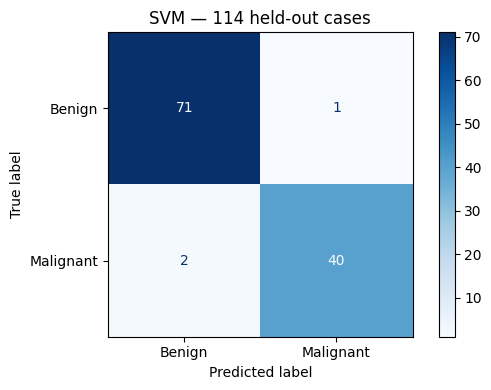

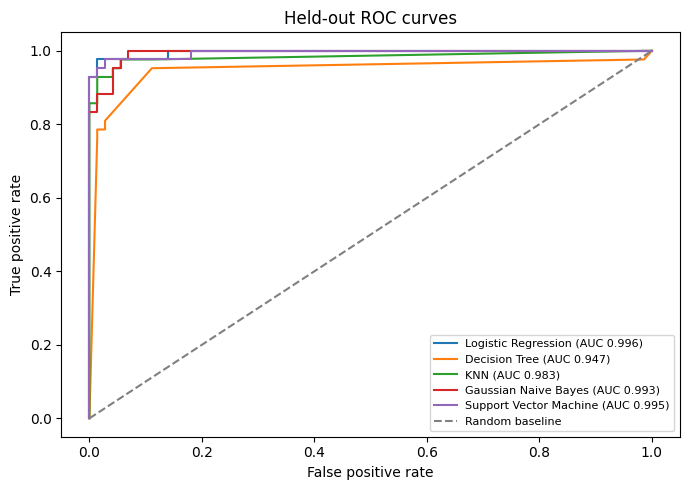

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_estimator(chosen, X_test, y_test, labels=[0, 1],
                                      display_labels=["Benign", "Malignant"], ax=ax, cmap="Blues")
ax.set_title("SVM — 114 held-out cases")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for model_name, pipeline in all_fitted.items():
    positive_column = list(pipeline.classes_).index(1)
    scores = pipeline.predict_proba(X_test)[:, positive_column]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, scores)
    ax.plot(false_positive_rate, true_positive_rate, label=f"{model_name} (AUC {roc_auc_score(y_test, scores):.3f})")
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random baseline')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='Held-out ROC curves')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 8. Independently reproduce the shipped saved models

The Streamlit app loads the five `.joblib` pipelines in `model/` and applies `.predict()` and `.predict_proba()` to **new labeled test CSV rows**; it does not call `.fit()`. This cell checks that the saved artifacts reproduce the table.

In [17]:
import json
import joblib
metadata = json.loads((PROJECT_ROOT / 'results' / 'experiment.json').read_text())
test_csv = pd.read_csv(PROJECT_ROOT / 'test_data.csv')
assert metadata['feature_names'] == feature_columns
for model_name, file_name in metadata['model_artifacts'].items():
    trained_model = joblib.load(PROJECT_ROOT / 'model' / file_name)
    model_scores = evaluate_classifier(trained_model, test_csv[feature_columns],
                                       test_csv['diagnosis'].map({'B': 0, 'M': 1}))
    print(model_name, 'Accuracy:', round(model_scores['Accuracy'], 4), 'MCC:', round(model_scores['MCC'], 4))

Logistic Regression Accuracy: 0.9649 MCC: 0.9245
Decision Tree Accuracy: 0.9035 MCC: 0.7926
KNN Accuracy: 0.9561 MCC: 0.9058
Gaussian Naive Bayes Accuracy: 0.9386 MCC: 0.8715
Support Vector Machine Accuracy: 0.9737 MCC: 0.9433


## 9. Final results for asked questions
(a) Which method achieves the highest test MCC? \
    -> Support Vector Machine, with MCC 0.9433 \
(b) Which has the highest AUC? \
    -> Logistic Regression, with AUC 0.9960 \
(c) Does your chosen winner also have the highest average CV MCC? \
    -> Yes. SVM has the highest CV MCC mean at 0.9492 \
(d) Why do false negatives matter when defining the malignant positive class? \
    -> The malignant class is encoded as the positive class (1), so a false negative is a malignant tumour predicted as benign. That patient would be told they are fine and could go untreated. A false positive only sends a benign case for extra checks. Recall (TP / (TP + FN)) measures exactly this, so a model with high recall misses fewer cancers. SVM has the best malignant recall (0.9524, 2 missed cases). Decision Tree has the worst (0.7857, 9 missed). Naive Bayes shows why accuracy alone can mislead: its precision is a perfect 1.0000, but it misses 7 malignant cases (recall 0.8333). \
(e) What evidence proves that the Streamlit app does not retrain on uploaded CSV? \
    -> The evidence is in the project: \
    1. No fitting code: app.py never calls .fit(). It only calls joblib.load() on the five saved model files, then predict, predict_proba and the metric functions on the uploaded data. \
    2. Same scores every time: the app’s scores for test_data.csv match the training output exactly. For example, SVM shows Accuracy 0.9737 and MCC 0.9433 in the app, as in your table. Retraining on an uploaded file would change the numbers. \
    3. Models stay untouched: the .joblib files keep the same timestamp and size after you upload a CSV. \
    4. Automated test: test_models_are_fitted_and_scores_reproduce loads the saved models and checks they reproduce the recorded metrics without any fitting. \
    5. Wording in the app: the “What each score means” section states that uploading a CSV never refits a model. \
